### TEL351 – Seminario de Telemática I
# Clase 12: Influence and Homophily
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Fuerzas sociales

Las fuerzas sociales conectan personas de diferentes maneras.

<div align="center">
    <img src="img/social-force.png" alt="" width="40%" align="center" />
</div>

## ¿Por qué las personas se vinculan?

<div align="center">
    <img src="img/diagram.jpg" alt="" width="60%" align="center" />
</div>

# Influencia

- Proceso mediante el cual un usuario (es decir, influyente) afecta o incide sobre otro usuario sin el uso aparente de la fuerza o extorsión.
- El usuario influenciado se vuelve más parecido a la figura influyente.

<div align="center">
    <img src="img/influencia-social.jpg" alt="" width="50%" align="center" />
</div>

## The Influentials (Keller & Berry)

<div align="right">
    <img src="img/The_Influentials.jpg" alt="" width="20%" align="right" />
</div>

El libro se basa en investigaciones que sugieren que aproximadamente el 10% de la población ejerce una influencia desproporcionadamente alta sobre el comportamiento y las opiniones de los demás. Keller y Berry argumentan que los influyentes comparten las siguientes características:

1. **Reconocimiento:** Son reconocidos por los demás.
2. **Generación:** Sus actividades son seguidas por los demás.
3. **Novedad:** Muestran perspectivas novedosas.
4. **Elocuencia:** Son elocuentes.

## Modelado de la influencia

Al tiempo $t_1$, el nodo $v$ está activado y el nodo $u$ no.

<div align="center">
    <img src="img/T1.jpg" alt="" width="20%" align="center" />
</div>

El nodo $u$ se activa debido a la influencia en el tiempo $t_2$.

<div align="center">
    <img src="img/T2.jpg" alt="" width="20%" align="center" />
</div>

Una vez activado, un nodo no se puede desactivar.

### Consideraciones

- El proceso de influencia siempre tiene lugar en una red.
- A veces esta red es observable y a veces no:
    - Red observable: Podemos observar a los usuarios influyentes en la red.
    - Red implícita: No podemos observar a los usuarios responsables de influir en otros (los influyentes), sino sólo a aquellos que son influenciados.

### Modelado de una red observable

Las redes observables se pueden modelar con un simple, pero efectivo modelo de umbral lineal o **Linear Threshold Model** (LTM).

- Un nodo $i$ se activa si la influencia entrante ($w_{j,i}$) de sus vecinos supera un cierto umbral $\theta$:

$$ \sum_{v_j \in N(v_i)} w_{j,i} \geq \theta_i $$

- Esto se calcula iterativamente para todos los nodos inactivos hasta que todos sean nodos activos o no hayan cambios entre una iteración y otra.

# Segregación racial

El modelo Linear Threshold Model (LTM) puede producir "segregación racial" en comunidades, incluso cuando los individuos no tienen un fuerte deseo de segregación.

## Modelo de segregación de Schelling

Cada agente tiene una preferencia por la composición racial de su vecindario (un umbral define cuántos de sus vecinos deben ser de la misma raza para sentirse cómodos). Si el número de vecinos de la misma raza cae por debajo del umbral de un agente, ese agente se siente incómodo y decide mudarse a otra ubicación. Aunque cada individuo tiene un umbral relativamente bajo (solo necesita unos pocos vecinos de la misma raza para sentirse cómodo), el resultado del modelo muestra que, con el tiempo, la comunidad tiende a separarse en grupos racialmente homogéneos. Esto se debe a que cuando un agente se muda, crea un efecto dominó, lo que lleva a que otros agentes se muden también. Por lo tanto, una acumulación de pequeñas decisiones individuales basadas en preferencias raciales producen un resultado colectivo.


<video width="384" height="216" controls src="img/Schelling.mp4" />

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML
import matplotlib.animation as animation

# Inicialización del grid
def initialize_grid(grid_size, empty_ratio):
    num_cells = grid_size * grid_size
    num_empty = int(empty_ratio * num_cells)
    num_agents = num_cells - num_empty
    
    # Crear una lista de agentes, 1 = tipo A, -1 = tipo B, 0 = vacío
    agents = np.array([1] * (num_agents // 2) + [-1] * (num_agents // 2) + [0] * num_empty)
    np.random.shuffle(agents)
    return agents.reshape((grid_size, grid_size))

# Función para calcular la similitud local
def calculate_similarity(grid, row, col):
    agent = grid[row, col]
    if agent == 0:  # Si es una celda vacía
        return 1  # No hay problema de "insatisfacción"

    # Vecindad de 8 celdas
    neighborhood = grid[max(0, row - 1):min(grid_size, row + 2), 
                        max(0, col - 1):min(grid_size, col + 2)]
    
    # Contar agentes similares en la vecindad (excluyendo la propia celda)
    total_neighbors = np.sum(neighborhood != 0) - 1  # Quita la celda central
    similar_neighbors = np.sum(neighborhood == agent) - 1
    
    # Si no hay vecinos, considera la celda como satisfecha
    if total_neighbors == 0:
        return 1
    return similar_neighbors / total_neighbors

# Mover agentes insatisfechos
def update_grid(grid):
    unsatisfied_agents = []
    
    # Verificar cada celda y encontrar agentes insatisfechos
    for row in range(grid_size):
        for col in range(grid_size):
            agent = grid[row, col]
            if agent != 0:  # Solo considera celdas no vacías
                similarity = calculate_similarity(grid, row, col)
                if similarity < similarity_threshold:
                    unsatisfied_agents.append((row, col))
    
    # Mover agentes insatisfechos a celdas vacías
    np.random.shuffle(unsatisfied_agents)
    empty_cells = list(zip(*np.where(grid == 0)))
    np.random.shuffle(empty_cells)
    
    for (row, col), (new_row, new_col) in zip(unsatisfied_agents, empty_cells):
        # Mover agente a una nueva celda vacía
        grid[new_row, new_col], grid[row, col] = grid[row, col], 0

# Configurar la visualización
def animate(i, grid, img):
    update_grid(grid)
    img.set_data(grid)
    return img,

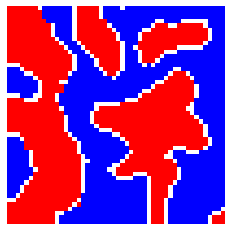

In [2]:
# Parámetros del modelo
grid_size = 50         # Tamaño de la cuadrícula
empty_ratio = 0.1      # Proporción de celdas vacías
similarity_threshold = 0.6  # Nivel de tolerancia de los agentes (0 a 1)

# Inicializar la cuadrícula y la animación
grid = initialize_grid(grid_size, empty_ratio)
fig, ax = plt.subplots()
img = ax.imshow(grid, cmap='bwr', vmin=-1, vmax=1)
ax.axis('off')

ani = animation.FuncAnimation(fig, animate, fargs=(grid, img), frames=100, interval=200, repeat=False)
HTML(ani.to_jshtml())

### Modelado de una red implícita

La información disponible:

* El conjunto de individuos **influenciados** en cualquier momento, $𝑃(𝑡)$.
* Tiempo $𝑡_𝑢$, donde cada individuo $𝑢$ es inicialmente influenciado (activado).
* Supongamos que cualquier usuario influenciado $𝑢$ puede influir en $𝐼(𝑢,𝑡)$ usuarios no influenciados después de $𝑡$ pasos.
* Podemos formular el tamaño de la población de influencia como:

$$ |𝑃(𝑡)| = \sum_{𝑢 \in 𝑃(𝑡)} 𝐼(𝑢,𝑡-𝑡_𝑢) $$

#### El tamaño de la población influenciada

<div align="right">
    <img src="img/implicit_influence.jpg" alt="" width="30%" align="right" />
</div>

Los individuos $𝑢$, $𝑣$ y $𝑤$ se activan en los instantes de tiempo $𝑡_𝑢$, $𝑡_𝑣$ y $𝑡_𝑤$, respectivamente.

En el momento $𝑡$, el número total de individuos influenciados es la suma de las funciones de influencia $𝐼_𝑢$, $𝐼_𝑣$ y $𝐼_𝑤$ en los instantes de tiempo $𝑡−𝑡_𝑢$, $𝑡−𝑡_𝑣$ y $𝑡−𝑡_𝑤$, respectivamente.

## Medición de la influencia

<div align="center">
    <img src="img/medidor.png" alt="" width="20%" align="center" />
</div>

La influencia se puede medir basándose en (1) la predicción o (2) la observación.

### Medición basada en predicción

Predice cuán influyente será un usuario en base a su posición dentro de la red.

<div align="center">
    <img src="img/likes.png" alt="" width="10%" align="center" />
    <img src="img/influencer.png" alt="" width="30%" align="center" />
</div>

### Medición basada en observación

Mide la cantidad de influencia atribuida al usuario.

<div align="center">
    <img src="img/observation.png" alt="" width="50%" align="center" />
</div>

#### I. Cuando un individuo es el modelo a seguir

Esto sucede con celebridades o personas destacadas. En este caso, se mide el tamaño de la audiencia que se ha visto influenciada por esa moda, carisma o acciones.

<div align="center">
    <img src="img/Gandhi.jpg" alt="" width="30%" align="center" />
</div>

#### II. Cuando un individuo difunde información.

Este escenario es más probable cuando una información, una epidemia o un producto se están difundiendo en una red. En este caso, se mide el tamaño de la cascada.

<div align="center">
    <img src="img/spreading.jpg" alt="" width="20%" align="center" />
</div>

#### III. Cuando la participación de un individuo aumenta el valor de un artículo o acción.

Cuando los individuos realizan acciones como comprar un producto, aumentan el valor del producto para otros individuos. Por ejemplo, la primera persona que compró una máquina de fax no tenía a quién enviarle faxes. La segunda persona que compró una máquina de fax aumentó su valor para la primera. Por lo tanto, se mide el aumento (o tasa de aumento) en el valor de un artículo o acción (como comprar un producto).

<div align="center">
    <img src="img/fax.jpg" alt="" width="20%" align="center" />
</div>

# Homofilia

Es la tendencia de las personas a asociarse y vincularse con otras similares. Las personas interactúan más a menudo con personas que son como ellos.

<div align="center">
    <img src="img/homofilia.png" alt="" width="70%" align="center" />
</div>

A diferencia de la influencia, donde un influyente influye en otros, en la homofilia, dos individuos similares deciden conectarse.

# Influence vs Homophily

- Influencia: "Los amigos se vuelven similares", 
- Homofilia: "Individuos similares se vuelven amigos".

<div align="center">
    <img src="img/influence-vs-homophily.jpg" alt="" width="40%" align="center" />
</div>

## Medición nominal de la homofilia

La homofilia se puede medir por medio de atributos nominales asignados a los nodos como raza o nacionalidad, género o similares. Una técnica sencilla es considerar el número de aristas que hay entre nodos del mismo tipo. Sea $t(𝑢_i)$ el tipo del nodo $𝑢_i$, en un grafo no dirigido, esta medida se puede calcular de la siguiente manera:

$$ \frac{1}{m} \sum_{(𝑢_i,𝑢_j) \in E} \delta (t(𝑢_i),t(𝑢_j)),  $$

donde $m$ es el número de aristas, $1/m$ se aplica para normalizar y $\delta$ es la función de Kronecker:

$$ \delta(x,y) = {\begin{cases}0,&{\text{si }}x\neq y;\\1,&{\text{si }}x=y.\end{cases}} $$

### Ejemplo

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import math

In [2]:
def nominal_homophily(G):
    summation = 0
    for x,y in G.edges:
        if G.nodes(data=True)[x] == G.nodes(data=True)[y]:
            summation += 1
    return summation/len(G.edges)

In [3]:
graph = nx.Graph()
graph.add_nodes_from([1, 2], color="lightpink")
graph.add_nodes_from([3, 4], color="lightblue")
edges_list = [[(1, 2), (3, 4)], [(1, 3), (2, 4)], [(1, 2), (3, 4), (2, 3)]]

In [4]:
def plot_nominal_homophily(graph, edges_list):    
    fig = plt.figure(figsize=(20,5))
    for i in range(len(edges_list)):
        edges = edges_list[i]
        G = nx.Graph(graph)
        G.add_edges_from(edges)
        pos = nx.spring_layout(G)
        node_colors = [node[1]['color'] for node in G.nodes(data=True)]
        plt.subplot(1, len(edges_list), i+1)
        nx.draw_networkx(G, pos, node_color=node_colors, node_size=500)
        plt.title(f"Homofilia Nominal: {round(nominal_homophily(G),2)}")
    plt.show()

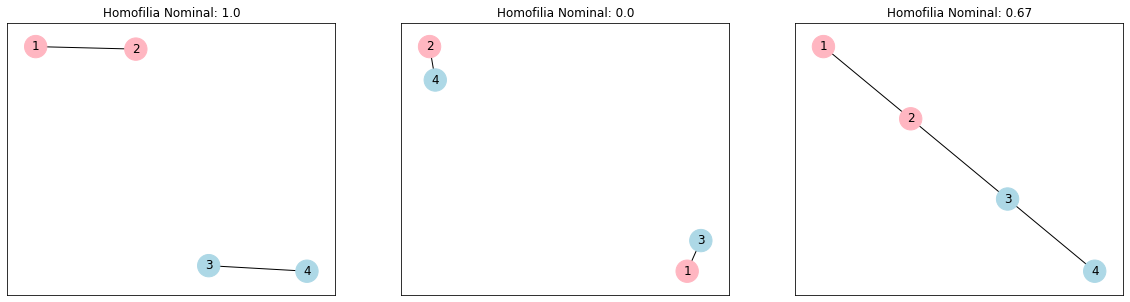

In [5]:
plot_nominal_homophily(graph, edges_list)

## Medición ordinal de la homofilia

Una medida común para analizar la relación entre dos variables con valores ordinales es la covarianza porque describe cómo dos variables cambian entre sí. En nuestro caso, nos interesa saber qué tan correlacionados están los valores de los atributos de los nodos conectados a través de aristas. Para esto, la función propuesta es el **el coeficiente de correlación de Pearson**.

$$ {\displaystyle \rho _{X,Y}={\sigma _{XY} \over \sigma _{X}\sigma _{Y}}={\frac {\operatorname {Cov} (X,Y)}{\sqrt {\operatorname {Var} (X)\operatorname {Var} (Y)}}}}  $$


### Ejemplo

In [6]:
graph = nx.Graph()
graph.add_nodes_from([1, 2], size=100)
graph.add_nodes_from([3, 4], size=1000)
edges_list = [[(1, 2), (3, 4)], [(1, 3), (2, 4)], [(1, 2), (3, 4), (2, 3)]]

In [7]:
def plot_ordinal_homophily(graph, edges_list):
    fig = plt.figure(figsize=(20,5))
    for i in range(len(edges_list)):
        edges = edges_list[i]
        G = nx.Graph(graph)
        G.add_edges_from(edges)
        pos = nx.spring_layout(G)
        node_sizes = [node[1]['size'] for node in G.nodes(data=True)]
        plt.subplot(1, len(edges_list), i+1)
        nx.draw_networkx(G, pos, node_color='white',  node_size=node_sizes)     
        nodes = nx.draw_networkx_nodes(G, pos, node_color='white',  node_size=node_sizes)     
        nodes.set_edgecolor('k')
        plt.title(f"Homofilia Ordinal: {round(nx.numeric_assortativity_coefficient(G, 'size'),2)}")
    plt.show()

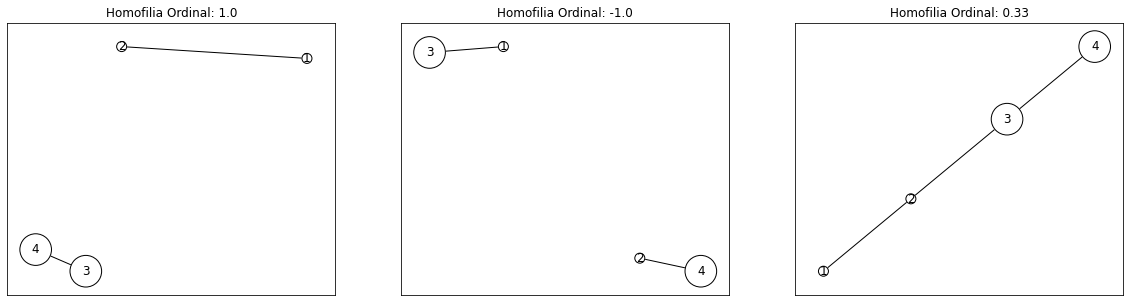

In [8]:
plot_ordinal_homophily(graph, edges_list)

# Confounding

Efecto del entorno al hacer que los individuos sean similares.

<div align="center">
    <img src="img/Confounding.png" alt="" width="60%" align="center" />
</div>

La fuerza de Confounding es un factor externo que es independiente de las interacciones interindividuales.

## La influencia de los entornos

Las personas y las cosas que nos rodean provocan un efecto en nuestro bienestar.

Los contextos en los que nos movemos pueden ser unos grandes aliados o unos grandes enemigos.

### Materiales

Los lugares donde se vive y se trabaja, el barrio y el vecindario, la tecnología, el automóvil, etc.

<div align="center">
    <img src="img/barrio.jpg" alt="" width="30%" align="center" />
</div>

### Personales

La familia, la pareja, los amigos, los compañeros de trabajo, los conocidos, el contacto en las redes sociales, los horarios y los hábitos.

<div align="center">
    <img src="img/familia.png" alt="" width="20%" align="center" />
</div>

### Mentales

Las creencias, los paradigmas, la formación e información, la religión o los condicionamientos.

<div align="center">
    <img src="img/creencias.png" alt="" width="80%" align="center" />
</div>

# Link Prediction

Los vínculos en redes sociales pueden ser entre usuarios (una nueva amistad amistad por ejemplo), un vínculo con una entidad o un vínculo con una comunidad. La predicción de enlaces es una tarea de análisis de redes y grafos donde el objetivo es predecir conexiones futuras entre nodos de una red.

<div align="center">
    <img src="img/link_prediction.png" alt="" width="50%" align="center" />
</div>

## Métodos para predecir enlaces

Los métodos más simples se basan en vecindarios:

- Common Neighbors: $ CN(u,v) = |\mathcal{N}(u) \cap \mathcal{N}(v)| $, señala que cuantos más amigos compartamos, más probabilidades tendremos de convertirnos en amigos.

- Jaccard: $ Jaccard(u,v) = \frac{|\mathcal{N}(u) \cap \mathcal{N}(v)|}{|\mathcal{N}(u) \cup \mathcal{N}(v)|} $, mide el hecho de que cuanto más similares sean nuestros círculos de amigos, más probabilidades habrá de que seamos amigos.

- Adamic Adar: $ AA(u,v) = \sum_{z \in \mathcal{N}(u) \cap \mathcal{N}(v)} \frac{1}{\log|\mathcal{N}(z)|} $, establece que cuanto más selectivos sean nuestros amigos en común, más probabilidades habrá de que nos hagamos amigos.

- Preferential Attachment: $ PA(u,v) = |\mathcal{N}(u)| \cdot |\mathcal{N}(v)| $, se basa en que las personas con muchos amigos son vistas como más atractivas para formar nuevos amigos.

In [9]:
df = pd.read_csv('simpsons.csv')

In [10]:
df

,Source,Source_Size,Target,Target_Size,Weight,Season
0,Marvin Monroe,3,Filmmaker,1,1,1
1,Bleeding Gums Murphy,2,Arcade boy,1,1,1
2,Girl with a headband,2,Tiny Tim,1,1,1
3,Moldy,2,Lucille Botzcowski,2,1,1
4,Mr. Winfield,3,Theater guy,1,1,1
...,...,...,...,...,...,...
441406,Homer Simpson,22,Squeaky-voiced teen,7,7,26
441407,Jimbo Jones,10,Baz,2,2,26
441408,Old father,1,Guitar Central employee,1,1,26
441409,Julius Hibbert's daughter,3,Neon sign store manager,1,1,26


In [11]:
def build_graph(df, season, threshold = 100):
    graph = nx.from_pandas_edgelist(df[df['Season'] == season], 
                                source='Source', target='Target', edge_attr='Weight', create_using=nx.Graph())
    for _, row in df[df['Season'] == season].iterrows():
        source = row['Source']
        target = row['Target']
        source_size = row['Source_Size']
        target_size = row['Target_Size']

        # Add size attributes to Source and Target nodes
        graph.nodes[source]['size'] = source_size
        graph.nodes[target]['size'] = target_size
        
    degrees = dict(nx.degree(graph))
    
    # Identify high-degree nodes
    high_degree_nodes = [node for node, degree in degrees.items() if degree > threshold]

    # Create spring layout with repulsion-only for high-degree nodes
    high_degree_graph = graph.subgraph(high_degree_nodes)
    high_degree_pos = nx.spring_layout(high_degree_graph, k=100)

    # Calculate positions for the rest of the nodes
    non_high_degree_nodes = set(graph.nodes()) - set(high_degree_nodes)
    non_high_degree_pos = nx.spring_layout(graph.subgraph(non_high_degree_nodes), k=0.1)

    # Merge positions of high-degree and non-high-degree nodes
    pos = {**high_degree_pos, **non_high_degree_pos}
    
    return graph, pos, degrees

In [12]:
def plot_network(graph, pos, degrees, season="None", threshold=100):
    plt.figure(figsize=(15, 8))
    
    edge_weights = [data['Weight']/20 for _, _, data in graph.edges(data=True)]
    #node_sizes = list({n:d[n]*200 for n in graph.nodes()}.values())
    node_sizes = [graph.nodes[node]['size']*200 for node in graph.nodes]
    labels = {n:n.replace(' ','\n') for n in graph.nodes() if degrees[n]>threshold}
    
    nx.draw_networkx_nodes(graph, pos, node_size=node_sizes, node_color='#F8DB27', edgecolors='black')
    nx.draw_networkx_edges(graph, pos, width=edge_weights, alpha=.5)
    nx.draw_networkx_labels(graph,pos,labels,font_size=10,font_weight='bold')
    plt.axis('off')
    plt.title(f"The Simpsons Season {season}",fontsize=16)
    plt.show()

In [13]:
def top_n_probable_links(graph, n, measures, measure='common_neighbors'):
    probable_links = {}

    # Iterate through all pairs of nodes
    for node1 in graph.nodes():
        for node2 in graph.nodes():
            if node1 != node2 and not graph.has_edge(node1, node2):
                
                # Calculate the specified link prediction measure
                measure_func = measures.get(measure, None)
                if measure_func:
                    centrality = measure_func(graph, node1, node2)

                    # Ensure that (x, y) and (y, x) are not both included
                    if (node1, node2) not in probable_links and (node2, node1) not in probable_links:
                        probable_links[(node1, node2)] = centrality

    # Sort the probable links by centrality in descending order
    sorted_links = sorted(probable_links.items(), key=lambda x: x[1], reverse=True)

    # Return the top-N probable links as a list of tuples
    return sorted_links[:n]

In [14]:
def link_prediction(graph, season, link_prediction_measure = 'common_neighbors', top_n = 5):

    measures = {
        'common_neighbors': lambda G, u, v: len(list(nx.common_neighbors(G, u, v))),
        'jaccard_coefficient': 
        lambda G, u, v: sum(1 for _ in nx.common_neighbors(G, u, v)) / len(set(G.neighbors(u)) | set(G.neighbors(v))),
        'preferential_attachment': lambda G, u, v: G.degree(u) * G.degree(v),
        'adamic_adar_index': lambda G, u, v: sum(1 / math.log(G.degree(w)) for w in nx.common_neighbors(G, u, v)),
    }
    
    print(f"Top {top_n} {link_prediction_measure} in season {season}")
    # Find the top-N most probable links using the specified measure
    top_links = top_n_probable_links(graph, top_n, measures)

    # Print the top-N links and their common neighbor centrality
    for link, centrality in top_links:
        x,y = link
        print(f"{x} and {y} : {centrality} neighbors")
    return top_links

In [15]:
def evaluate(df, top_links, season, timestep=9999):
    acc = 0
    for link, centrality in top_links:
        x,y = link
        y_test = df[((df['Source'] == x) & (df['Target'] == y) & (df["Season"] > season) ) | 
                    ((df['Source'] == y) & (df['Target'] == x) & (df["Season"] > season) )]['Season'].to_list()        
        if len(y_test) == 0:
            print(f"{x} and {y} are not linked in any season.")
        else:
            print(f"{x} and {y} are linked in seasons {','.join(map(str, y_test))}")
            if y_test[0] <= season + timestep:
                acc += 1
    acc = round((acc / len(top_links)),2)*100
    return acc

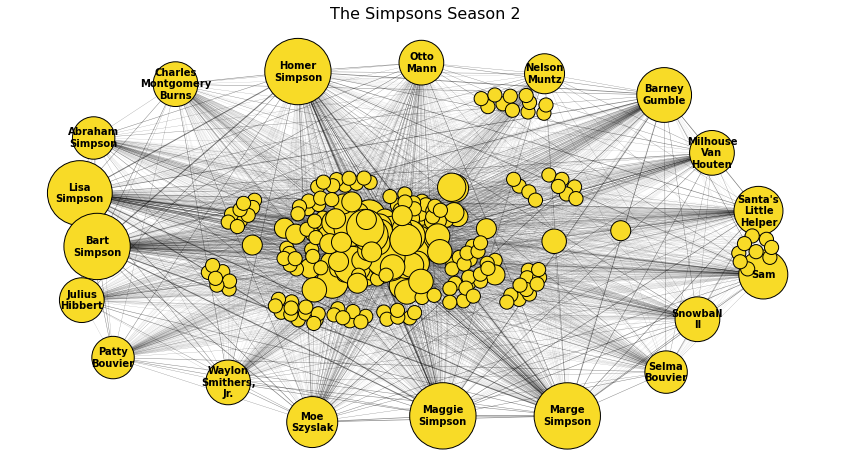

In [16]:
season = 2
threshold = 150
G, pos, degrees = build_graph(df, season, threshold)
plot_network(G, pos, degrees, season, threshold)

In [17]:
pred = link_prediction(G, season)

Top 5 common_neighbors in season 2
Patty Bouvier and Jasper Beardley : 63 neighbors
Selma Bouvier and Jasper Beardley : 63 neighbors
Bleeding Gums Murphy and Carl Carlson : 55 neighbors
Howard and Julius Hibbert : 54 neighbors
Jimbo Jones and Kent Brockman : 53 neighbors


In [18]:
evaluate(df, pred, season, timestep=1)

Patty Bouvier and Jasper Beardley are linked in seasons 3,5,6,22
Selma Bouvier and Jasper Beardley are linked in seasons 3,5,6,22
Bleeding Gums Murphy and Carl Carlson are linked in seasons 3,4,5,6,7,8,13,20,21,23,24,25,26
Howard and Julius Hibbert are linked in seasons 4,6,8,11
Jimbo Jones and Kent Brockman are linked in seasons 3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26


80.0

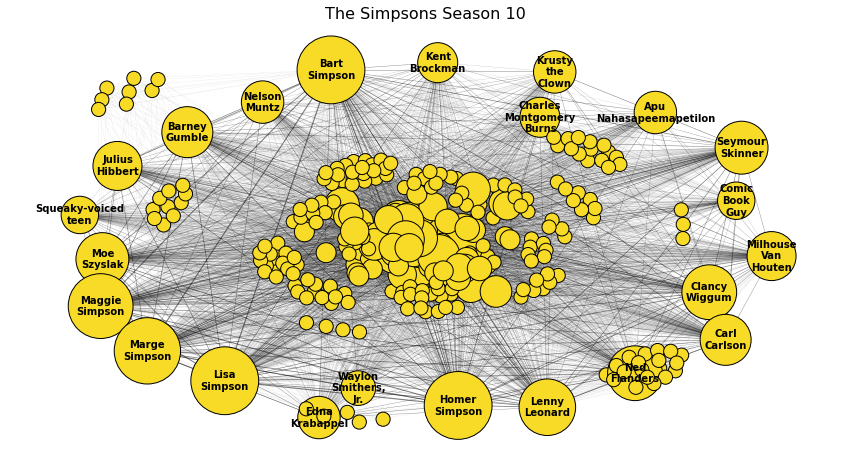

In [19]:
season = 10
threshold = 150
G, pos, degrees = build_graph(df, season, threshold)
plot_network(G, pos, degrees, season, threshold)

In [20]:
pred = link_prediction(G, season)

Top 5 common_neighbors in season 10
Agnes Skinner and Snowball II : 59 neighbors
Groundskeeper Willie and Snowball II : 58 neighbors
Jonathan Frink and Horatio McCallister : 55 neighbors
Charles Montgomery Burns and Horatio McCallister : 55 neighbors
Sarah Wiggum and Joe Quimby : 55 neighbors


In [21]:
evaluate(df, pred, season, timestep=1)

Agnes Skinner and Snowball II are linked in seasons 12,13,14,15,16,17,23
Groundskeeper Willie and Snowball II are linked in seasons 11,12,13,14,15,16,17,18,23
Jonathan Frink and Horatio McCallister are linked in seasons 11,12,13,14,15,16,17,18,19,20,22,23,24,25,26
Charles Montgomery Burns and Horatio McCallister are linked in seasons 11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
Sarah Wiggum and Joe Quimby are linked in seasons 12,13,14,15,16,17,18,19,20,21,22,23,24,25,26


60.0